# A* Search
**The bellow is the task 1 for the assignment**

A* Search is an **informed search algorithm** that combines the actual cost from the start node with the estimated cost from the current node to the goal.

\[
f(n) = g(n) + h(n)
\]

Where:

- **\(g(n)\)**: Actual cost from the start state to node \(n\).
- **\(h(n)\)**: Estimated cost from node \(n\) to the goal.
- **\(f(n)\)**: Estimated total cost of a solution through node \(n\).

A* always expands the node with the **lowest \(f(n)\)** value.

Unlike **Greedy Best-First Search**, which considers only \(h(n)\), A* considers both the cost already incurred and the estimated future cost.

- **Tree Search:** A* is optimal if \(h(n)\) is **admissible**.

In [ ]:
import heapq       # priority queue (min-heap) — like you'd build in C
import math         # for sqrt
import networkx as nx
import matplotlib.pyplot as plt
%matplotlib inline

## Step 1 — Node coordinates
Each node's (x, y) position. This is what the heuristic (straight-line distance) will be computed from.

In [ ]:
nodes = {
    'Oradea': (131, 571),
    'Zerind': (108, 531),
    'Arad': (91, 492),
    'Timisoara': (94, 410),
    'Lugoj': (165, 379),
    'Mehadia': (168, 339),
    'Dobreta': (165, 299),
    'Sibiu': (207, 457),
    'Fagaras': (305, 449),
    'Rimnicu Vilcea': (233, 410),
    'Pitesti': (320, 368),
    'Craiova': (253, 288),
    'Bucharest': (400, 327),
    'Giurgiu': (375, 270),
    'Urziceni': (456, 350),
    'Hirsova': (534, 350),
    'Eforie': (562, 293),
    'Vaslui': (509, 444),
    'Iasi': (473, 506),
    'Neamt': (406, 537)
}


## Step 2 — Edges + weight (written directly)
Each edge is made of three things: `(node1, node2, weight)`. Every edge here has weight `1` — like building an array of `struct Edge { char u, v; int weight; }` in C.

In [ ]:
edges = [
    ('Oradea', 'Zerind', 71),
    ('Oradea', 'Sibiu', 151),
    ('Zerind', 'Arad', 75),
    ('Arad', 'Sibiu', 140),
    ('Arad', 'Timisoara', 118),
    ('Timisoara', 'Lugoj', 111),
    ('Lugoj', 'Mehadia', 70),
    ('Mehadia', 'Dobreta', 75),
    ('Dobreta', 'Craiova', 120),
    ('Sibiu', 'Rimnicu Vilcea', 80),
    ('Sibiu', 'Fagaras', 99),
    ('Rimnicu Vilcea', 'Craiova', 146),
    ('Rimnicu Vilcea', 'Pitesti', 97),
    ('Craiova', 'Pitesti', 138),
    ('Fagaras', 'Bucharest', 211),
    ('Pitesti', 'Bucharest', 101),
    ('Bucharest', 'Giurgiu', 90),
    ('Bucharest', 'Urziceni', 85),
    ('Urziceni', 'Hirsova', 98),
    ('Hirsova', 'Eforie', 86),
    ('Urziceni', 'Vaslui', 142),
    ('Vaslui', 'Iasi', 92),
    ('Iasi', 'Neamt', 87)
]

# Lowercase format (optional)
edges_lower = [(u.lower(), v.lower(), w) for u, v, w in edges]

# Straight-line distance to Bucharest (Heuristic table)
h_table = {
    'Arad': 366,
    'Bucharest': 0,
    'Craiova': 160,
    'Dobreta': 242,
    'Eforie': 161,
    'Fagaras': 178,
    'Giurgiu': 77,
    'Hirsova': 151,
    'Iasi': 226,
    'Lugoj': 244,
    'Mehadia': 241,
    'Neamt': 234,
    'Oradea': 380,
    'Pitesti': 98,
    'Rimnicu Vilcea': 193,
    'Sibiu': 253,
    'Timisoara': 329,
    'Urziceni': 80,
    'Vaslui': 199,
    'Zerind': 374
}

## Step 3 — Build the adjacency list
This is exactly like building an adjacency list from an edge array in C — two explicit loops, no shortcuts.

The graph is **undirected**, so for every edge `(u, v, w)` we add an entry on both sides: add `v` to `u`'s neighbour list, and add `u` to `v`'s neighbour list.

In [ ]:
def build_graph(edges):
    graph = {}   # dictionary = like a hash map / array-of-lists in C

    for u, v, w in edges:
        if u not in graph:
            graph[u] = []          # first time seeing this node, create an empty list
        if v not in graph:
            graph[v] = []

        graph[u].append((v, w))    # u -> v, cost w
        graph[v].append((u, w))    # v -> u, cost w (undirected, both directions)

    return graph

graph = build_graph(edges)

# sanity check: print the adjacency list to make sure it's correct
for node in graph:
    print(node, "->", graph[node])

Oradea -> [('Zerind', 71), ('Sibiu', 151)]
Zerind -> [('Oradea', 71), ('Arad', 75)]
Sibiu -> [('Oradea', 151), ('Arad', 140), ('Rimnicu Vilcea', 80), ('Fagaras', 99)]
Arad -> [('Zerind', 75), ('Sibiu', 140), ('Timisoara', 118)]
Timisoara -> [('Arad', 118), ('Lugoj', 111)]
Lugoj -> [('Timisoara', 111), ('Mehadia', 70)]
Mehadia -> [('Lugoj', 70), ('Dobreta', 75)]
Dobreta -> [('Mehadia', 75), ('Craiova', 120)]
Craiova -> [('Dobreta', 120), ('Rimnicu Vilcea', 146), ('Pitesti', 138)]
Rimnicu Vilcea -> [('Sibiu', 80), ('Craiova', 146), ('Pitesti', 97)]
Fagaras -> [('Sibiu', 99), ('Bucharest', 211)]
Pitesti -> [('Rimnicu Vilcea', 97), ('Craiova', 138), ('Bucharest', 101)]
Bucharest -> [('Fagaras', 211), ('Pitesti', 101), ('Giurgiu', 90), ('Urziceni', 85)]
Giurgiu -> [('Bucharest', 90)]
Urziceni -> [('Bucharest', 85), ('Hirsova', 98), ('Vaslui', 142)]
Hirsova -> [('Urziceni', 98), ('Eforie', 86)]
Eforie -> [('Hirsova', 86)]
Vaslui -> [('Urziceni', 142), ('Iasi', 92)]
Iasi -> [('Vaslui', 92), (

## Step 4 — Heuristic h(n)
h(n) = straight-line distance from the current node to the goal (Euclidean distance). Just the Pythagoras theorem — like writing `sqrt(dx*dx + dy*dy)` in C.

In [ ]:
def heuristic(node, goal):
    x1, y1 = nodes[node]
    x2, y2 = nodes[goal]
    dx = x1 - x2
    dy = y1 - y2
    return math.sqrt(dx * dx + dy * dy)

## Helper to draw the graph
(This is only for drawing — there's no A* logic in here, just take it as-is.)

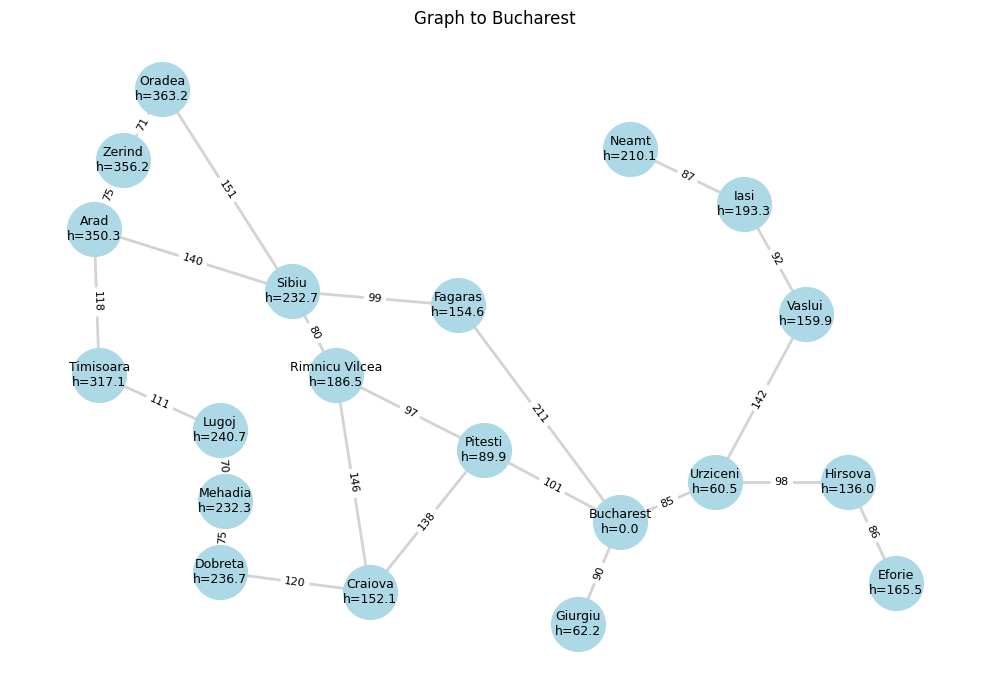

In [ ]:
def draw_graph(graph, goal=None, highlight_path=None, title=""):
    G_ = nx.Graph()
    for u in graph:
        for v, w in graph[u]:
            G_.add_edge(u, v, weight=w)

    plt.figure(figsize=(10, 7))
    nx.draw_networkx_edges(G_, nodes, edge_color='lightgray', width=2)
    nx.draw_networkx_nodes(G_, nodes, node_color='lightblue', node_size=1500)

    labels = {}
    for n in nodes:
        if goal is not None and goal in nodes:
            labels[n] = n + "\nh=" + str(round(heuristic(n, goal), 1))
        else:
            labels[n] = n
    nx.draw_networkx_labels(G_, nodes, labels=labels, font_size=9)

    edge_labels = nx.get_edge_attributes(G_, 'weight')
    nx.draw_networkx_edge_labels(G_, nodes, edge_labels=edge_labels, font_size=8)

    if highlight_path:
        path_edges = []
        for i in range(len(highlight_path) - 1):
            path_edges.append((highlight_path[i], highlight_path[i + 1]))

        nx.draw_networkx_edges(G_, nodes, edgelist=path_edges, edge_color='red', width=3)
        nx.draw_networkx_nodes(G_, nodes, nodelist=highlight_path, node_color='salmon', node_size=1500)
        nx.draw_networkx_nodes(G_, nodes, nodelist=[highlight_path[0]], node_color='lightgreen', node_size=1600)
        nx.draw_networkx_nodes(G_, nodes, nodelist=[highlight_path[-1]], node_color='gold', node_size=1600)

    plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Updated test call with valid node
draw_graph(graph, goal='Bucharest', title="Graph to Bucharest")

## Step 5 — A* Search (simple version)

Just like in C: keep a priority queue (`heapq`), and keep a `visited` set (like a `bool visited[N]` array).

Every step:
1. Pop the node with the smallest `f` value from the priority queue
2. If it's the goal — done, return the path
3. If it's already visited — skip it, move on
4. Otherwise, mark it visited, and push all of its neighbours into the queue

`f = g + h` , `g` = actual cost paid so far, `h` = estimated cost remaining to the goal.

In [ ]:
def astar_search(graph, start, goal):
    # each entry in the priority queue: (f, node_name, path_so_far, g)
    pq = []
    heapq.heappush(pq, (heuristic(start, goal), start, [start], 0))

    visited = set()   # like bool visited[N] = {False} in C

    while len(pq) > 0:
        f, node, path, g = heapq.heappop(pq)

        if node == goal:
            return path, g          # found it! return the path and total cost

        if node in visited:
            continue                # already processed this node, skip

        visited.add(node)

        for neighbor, cost in graph[node]:
            if neighbor not in visited:
                new_g = g + cost
                new_f = new_g + heuristic(neighbor, goal)   # f(n) = g(n) + h(n)
                heapq.heappush(pq, (new_f, neighbor, path + [neighbor], new_g))

    return None, None   # queue is empty, no path found to the goal

## Run it!
You can change `start` and `goal` here.

Path: Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
Total cost: 418


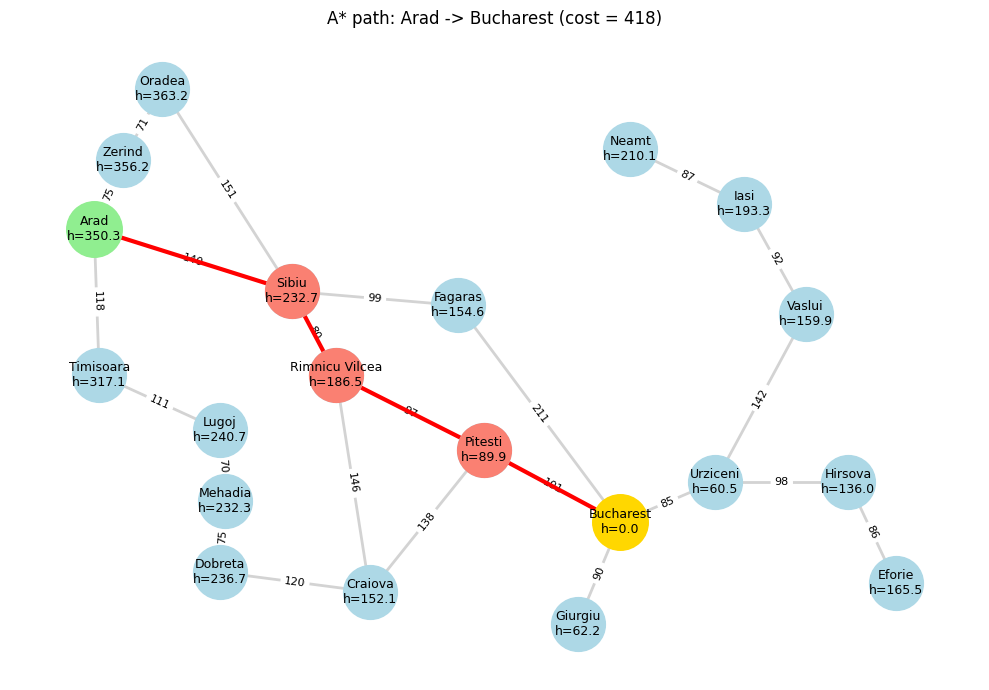

In [ ]:
start = 'Arad'
goal = 'Bucharest'

path, cost = astar_search(graph, start, goal)

if path is None:
    print("No path found.")
else:
    print("Path:", " -> ".join(path))
    print("Total cost:", cost)

    draw_graph(graph, goal=goal, highlight_path=path,
               title=f"A* path: {start} -> {goal} (cost = {cost})")

What is the difference between heuristic function and heuritics.?                  
 ans. A heuritics is a way of solving something with some data or intuition it may not give the the answer all the times . where as the heuristic function will always give answer .


in the task 1 for the cross verfication we can see that for some any other path the cost of reaching it is always more .

# **Task 2** : Admissible vs. Inadmissible heuristic


In [ ]:
h_wrongtable = {
    'Arad': 366,
    'Bucharest': 0,
    'Craiova': 160,
    'Dobreta': 242,
    'Eforie': 161,
    'Fagaras': 178,
    'Giurgiu': 77,
    'Hirsova': 151,
    'Iasi': 226,
    'Lugoj': 244,
    'Mehadia': 241,
    'Neamt': 234,
    'Oradea': 380,
    'Pitesti': 98,
    'Rimnicu Vilcea': 5000,
    'Sibiu': 1000,
    'Timisoara': 329,
    'Urziceni': 80,
    'Vaslui': 199,
    'Zerind': 374
}
#here i have change and written the wrong value in for the sibiu city and Rimnicu Vilcea.


In [ ]:
def astar_search_with_h(graph, start, goal, h_dict):
    # A version of A* that uses a pre-defined heuristic dictionary
    pq = []
    # f = g + h. Here g=0 for the start node
    heapq.heappush(pq, (h_dict[start], start, [start], 0))

    visited = set()

    while pq:
        f, node, path, g = heapq.heappop(pq)

        if node == goal:
            return path, g

        if node in visited:
            continue

        visited.add(node)

        for neighbor, cost in graph[node]:
            if neighbor not in visited:
                new_g = g + cost
                new_f = new_g + h_dict[neighbor]
                heapq.heappush(pq, (new_f, neighbor, path + [neighbor], new_g))

    return None, None

Path: Arad -> Timisoara -> Lugoj -> Mehadia -> Dobreta -> Craiova -> Pitesti -> Bucharest
Total cost: 733


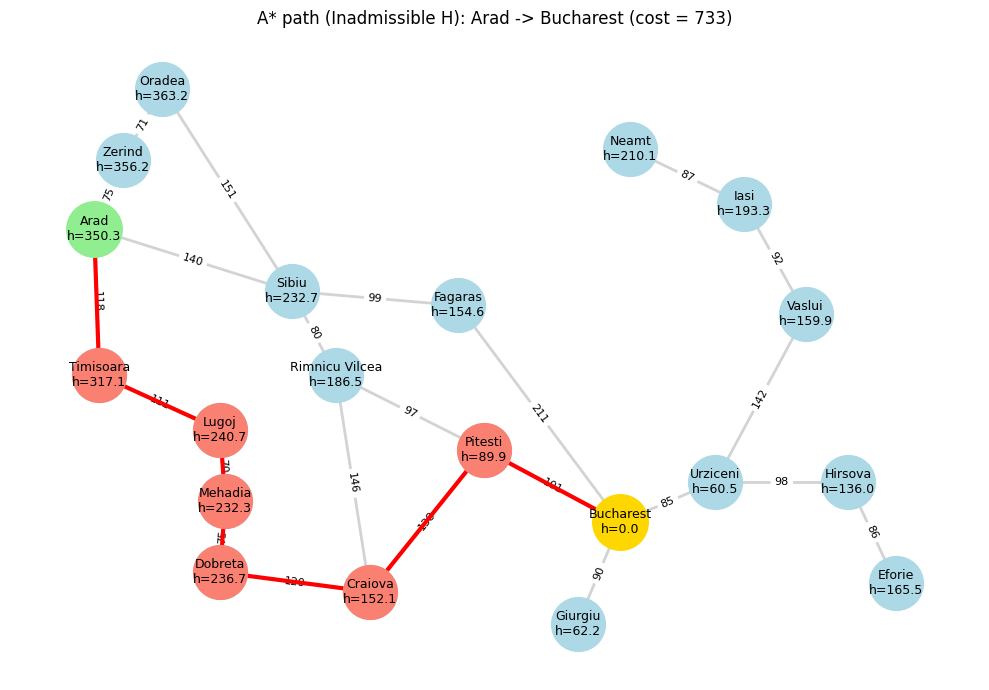

In [ ]:
start = 'Arad'
goal = 'Bucharest'

# Using the new function that accepts the h_wrongtable dictionary
path, cost = astar_search_with_h(graph, start, goal, h_wrongtable)

if path is None:
    print("No path found.")
else:
    print("Path:", " -> ".join(path))
    print("Total cost:", cost)

    draw_graph(graph, goal=goal, highlight_path=path,
               title=f"A* path (Inadmissible H): {start} -> {goal} (cost = {cost})")

### Task 2 Result: Inadmissible Heuristic
The error previously in this cell was due to passing a dictionary into the original A* function which only accepted city names.

As seen in the results from `astar_search_with_h` above:
- **Admissible Heuristic (Task 1):** Cost = 418
- **Inadmissible Heuristic (Task 2):** Cost = 733

Because the heuristic for Sibiu and Rimnicu Vilcea was significantly overestimated (1000 and 5000), the algorithm avoided the optimal path, demonstrating how an inadmissible heuristic loses the optimality guarantee of A*.

this shows that how much important it is for the heuristic function / values to be correct to get the accurate value .

# **Task 3** :  Greedy best-first search

In [ ]:
def gready_best_first_search(graph, start, goal):
    # each entry in the priority queue: (f, node_name, path_so_far, g)
    pq = []
    heapq.heappush(pq, (heuristic(start, goal), start, [start], 0))

    visited = set()   # like bool visited[N] = {False} in C

    while len(pq) > 0:
        f, node, path, g = heapq.heappop(pq)

        if node == goal:
            return path, g          # found it! return the path and total cost

        if node in visited:
            continue                # already processed this node, skip

        visited.add(node)

        for neighbor, cost in graph[node]:
            if neighbor not in visited:
                new_g = g + cost
                new_f =heuristic(neighbor, goal)   # f(n) = h(n)-----> here is the change and this makes it the so be are making decision soley based on the heuristic function
                heapq.heappush(pq, (new_f, neighbor, path + [neighbor], new_g))

    return None, None   # queue is empty, no path found to the goal

Path: Iasi -> Vaslui -> Urziceni -> Bucharest -> Fagaras
Total cost: 530


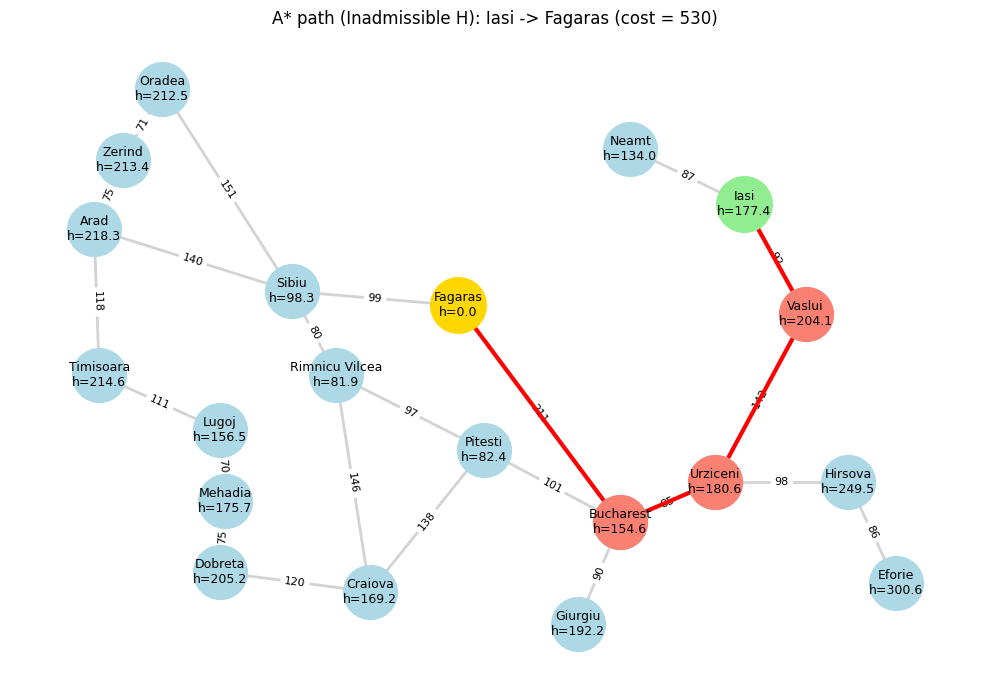

In [35]:
start = 'Iasi'
goal = 'Fagaras'

# Using the new function that accepts the h_wrongtable dictionary
path, cost = gready_best_first_search(graph, start, goal)

if path is None:
    print("No path found.")
else:
    print("Path:", " -> ".join(path))
    print("Total cost:", cost)

    draw_graph(graph, goal=goal, highlight_path=path,
               title=f"A* path (Inadmissible H): {start} -> {goal} (cost = {cost})")

### Comparison: Where Greedy Best-First Search fails to be Optimal
Greedy Best-First Search is 'greedy' because it always takes the node that *appears* closest to the goal. In the example below (Oradea to Bucharest), we compare A* (which is optimal) with GBFS.

In [34]:
start_node = 'Oradea'
goal_node = 'Bucharest'

# 1. Run A*
path_astar, cost_astar = astar_search(graph, start_node, goal_node)

# 2. Run Greedy Best-First
path_gbfs, cost_gbfs = gready_best_first_search(graph, start_node, goal_node)

print(f"--- Comparison for {start_node} to {goal_node} ---")
print(f"A* Search Path:      {' -> '.join(path_astar)}")
print(f"A* Total Cost:       {cost_astar}")
print("-" * 40)
print(f"Greedy BFS Path:     {' -> '.join(path_gbfs)}")
print(f"Greedy BFS Cost:     {cost_gbfs}")

if cost_gbfs > cost_astar:
    print(f"\nObservation: Greedy BFS took a sub-optimal path through Fagaras.")
    print(f"It saved {cost_astar - cost_astar} at the moment but ended up costing {cost_gbfs - cost_astar} more total.")

--- Comparison for Oradea to Bucharest ---
A* Search Path:      Oradea -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
A* Total Cost:       429
----------------------------------------
Greedy BFS Path:     Oradea -> Sibiu -> Fagaras -> Bucharest
Greedy BFS Cost:     461

Observation: Greedy BFS took a sub-optimal path through Fagaras.
It saved 0 at the moment but ended up costing 32 more total.


here in the above example we can see that the shortest distance is a sub optimal path and also
```markdown
**Example 2: Minimal Dead-End Graph Trap**

A simple 4-node graph illustrates why local heuristic minimums trick Greedy Best-First Search (GBFS):

```text
       S (Start)
      / \
     /   \
    A     B
(Dead)     \
            G (Goal)

```

### **Why Greedy BFS Gets Stuck**

* **Ignores Path Cost $g(n)$:** It only considers estimated distance remaining ($h(n)$), completely ignoring the path cost already incurred ($g(n)$).
* **Local Minima Traps:** It blindly moves toward nodes with smaller $h(n)$ values, even if those nodes lead into dead ends or infinite cycles away from the actual goal.

```

```